In [52]:
import pandas as pd

# Load dataset from CSV file
df = pd.read_csv('data_asof_0501.csv')

# Convert all binary 0/1 columns except 'enrolled' to categorical type
df['app_completed'] = df['app_completed'].astype('category')
df['admitted'] = df['admitted'].astype('category')
df['deposit_paid'] = df['deposit_paid'].astype('category')
df['first_generation'] = df['first_generation'].astype('category')
df['legacy'] = df['legacy'].astype('category')
df['stealth'] = df['stealth'].astype('category')
df['grad_expct'] = df['grad_expct'].astype('category')
df['ed_plan_asst'] = df['ed_plan_asst'].astype('category')
df['wrtng_asst'] = df['wrtng_asst'].astype('category')
df['read_asst'] = df['read_asst'].astype('category')
df['study_skll_asst'] = df['study_skll_asst'].astype('category')
df['math_asst'] = df['math_asst'].astype('category')
df['rotc_interest'] = df['rotc_interest'].astype('category')
df['veteran'] = df['veteran'].astype('category')
df['stem_major'] = df['stem_major'].astype('category')
df['urm'] = df['urm'].astype('category')

In [53]:
# Split the dataset into features (X) and target variable (y)
X = df.drop('enrolled', axis=1)
y = df['enrolled']

### 2. Feature Selection

In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Use predictors that are available before the enrollment outcome.
# Numeric academic/application predictors are now included alongside categorical predictors.
numeric_columns = [
    'hs_gpa', 'act_cmpst', 'act_engl', 'act_math',
    'sat_comb', 'sat_vrbl', 'sat_math', 'hs_math', 'hs_sci',
    'hs_engl', 'hs_ss', 'hs_flang', 'hs_rank', 'campus_visit_tot',
    'coll_algbr_cr', 'coll_geom_cr', 'coll_trig_cr', 'coll_calc_cr',
    'coll_math', 'coll_sci', 'miles_from_campus', 'age', 'app_days_before_start'
]
categorical_columns = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Impute missing values before encoding so training and future demo inputs use the same rules.
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_columns),
    ('categorical', categorical_pipeline, categorical_columns)
], sparse_threshold=1.0)

X_processed = preprocessor.fit_transform(X)
feature_names = preprocessor.get_feature_names_out()

# Use all available CPU cores for the selector forest; this is not the final model.
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf.fit(X_processed, y)

importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

display(importance_df.head(50))

C:\Users\manth\AppData\Local\Temp\ipykernel_14632\2517125546.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=['object', 'category']).columns.tolist()


,feature,importance
25,categorical__acceptance_fee_NotPaid,0.266051
32,categorical__deposit_paid_1,0.232360
26,categorical__acceptance_fee_Paid,0.207411
20,numeric__miles_from_campus,0.029737
13,numeric__campus_visit_tot,0.027097
22,numeric__app_days_before_start,0.023921
0,numeric__hs_gpa,0.020870
12,numeric__hs_rank,0.017256
2,numeric__act_engl,0.014585
29,categorical__residency_Resident,0.014021


In [55]:
# Retain numeric and encoded categorical features above the importance threshold.
selected_feature_names = importance_df.loc[
    importance_df['importance'] > 0.001, 'feature'
].tolist()
selected_feature_indices = [
    list(feature_names).index(feature) for feature in selected_feature_names
]
X_filtered = X_processed[:, selected_feature_indices]
print(f'Retained {len(selected_feature_names)} of {len(feature_names)} processed features.')


Retained 49 of 52 processed features.


### 3. Model Training and Comparison

In [56]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MaxAbsScaler

X_filtered_norm = MaxAbsScaler().fit_transform(X_filtered)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_filtered_norm, y, test_size=0.2, random_state=42)

#### Logistic Regression

In [57]:
from sklearn.linear_model import LogisticRegression

# Train a logistic regression model
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

# Make predictions
y_pred_logreg = logreg.predict(X_test)

#### Lasso Regression

In [58]:
from sklearn.linear_model import Lasso

# Train a Lasso regression model
lasso = Lasso(alpha=0.01)
lasso.fit(X_train, y_train)

# Make predictions
y_pred_lasso = lasso.predict(X_test)

#### ElasticNet

In [59]:
from sklearn.linear_model import ElasticNet

# Train an Elastic Net regression model
elastic_net = ElasticNet(alpha=0.01, l1_ratio=0.5)
elastic_net.fit(X_train, y_train)

# Make predictions
y_pred_elastic_net = elastic_net.predict(X_test)

#### Ridge Regression

In [60]:
from sklearn.linear_model import Ridge

# Train a Ridge regression model
ridge = Ridge(alpha=0.01)
ridge.fit(X_train, y_train)

# Make predictions
y_pred_ridge = ridge.predict(X_test)

#### Random Forest Regression

In [61]:
from sklearn.ensemble import RandomForestRegressor

# Train a Random Forest regression model
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf.predict(X_test)

#### Gradient Boosting Regression

In [62]:
from sklearn.ensemble import GradientBoostingRegressor

# Train a Gradient Boosting regression model
gbr = GradientBoostingRegressor(n_estimators=100, random_state=42)
gbr.fit(X_train, y_train)

# Make predictions
y_pred_gbr = gbr.predict(X_test)

#### Model Comparison

In [63]:
# Compare the performance of different models using R-squared score, Root Mean Squared Error (RMSE), and Mean Absolute Error (MAE)
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

# Calculate metrics for each model
r2_logreg = r2_score(y_test, y_pred_logreg)
r2_lasso = r2_score(y_test, y_pred_lasso)
r2_elastic_net = r2_score(y_test, y_pred_elastic_net)
r2_ridge = r2_score(y_test, y_pred_ridge)
r2_rf = r2_score(y_test, y_pred_rf)
r2_gbr = r2_score(y_test, y_pred_gbr)

adj_r2_logreg = 1 - (1 - r2_logreg) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)
adj_r2_lasso = 1 - (1 - r2_lasso) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)
adj_r2_elastic_net = 1 - (1 - r2_elastic_net) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)
adj_r2_ridge = 1 - (1 - r2_ridge) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)
adj_r2_rf = 1 - (1 - r2_rf) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)
adj_r2_gbr = 1 - (1 - r2_gbr) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)

rmse_logreg = root_mean_squared_error(y_test, y_pred_logreg)
rmse_lasso = root_mean_squared_error(y_test, y_pred_lasso)
rmse_elastic_net = root_mean_squared_error(y_test, y_pred_elastic_net)
rmse_ridge = root_mean_squared_error(y_test, y_pred_ridge)
rmse_rf = root_mean_squared_error(y_test, y_pred_rf)
rmse_gbr = root_mean_squared_error(y_test, y_pred_gbr)

mae_logreg = mean_absolute_error(y_test, y_pred_logreg)
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
mae_elastic_net = mean_absolute_error(y_test, y_pred_elastic_net)
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mae_gbr = mean_absolute_error(y_test, y_pred_gbr)

# Create a DataFrame to display the metrics for each model
metrics_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Lasso Regression', 'Elastic Net Regression', 'Ridge Regression', 'Random Forest Regression', 'Gradient Boosting Regression'],
    'R-squared': [r2_logreg, r2_lasso, r2_elastic_net, r2_ridge, r2_rf, r2_gbr],
    'Adjusted R-squared': [adj_r2_logreg, adj_r2_lasso, adj_r2_elastic_net, adj_r2_ridge, adj_r2_rf, adj_r2_gbr],
    'RMSE': [rmse_logreg, rmse_lasso, rmse_elastic_net, rmse_ridge, rmse_rf, rmse_gbr],
    'MAE': [mae_logreg, mae_lasso, mae_elastic_net, mae_ridge, mae_rf, mae_gbr]
})

display(metrics_df)

,Model,R-squared,Adjusted R-squared,RMSE,MAE
0,Logistic Regression,0.756717,0.755849,0.231718,0.053693
1,Lasso Regression,0.777266,0.776471,0.221716,0.114282
2,Elastic Net Regression,0.777905,0.777112,0.221398,0.109205
3,Ridge Regression,0.783633,0.782861,0.218524,0.103031
4,Random Forest Regression,0.798195,0.797475,0.211042,0.092216
5,Gradient Boosting Regression,0.795411,0.794681,0.212493,0.094361


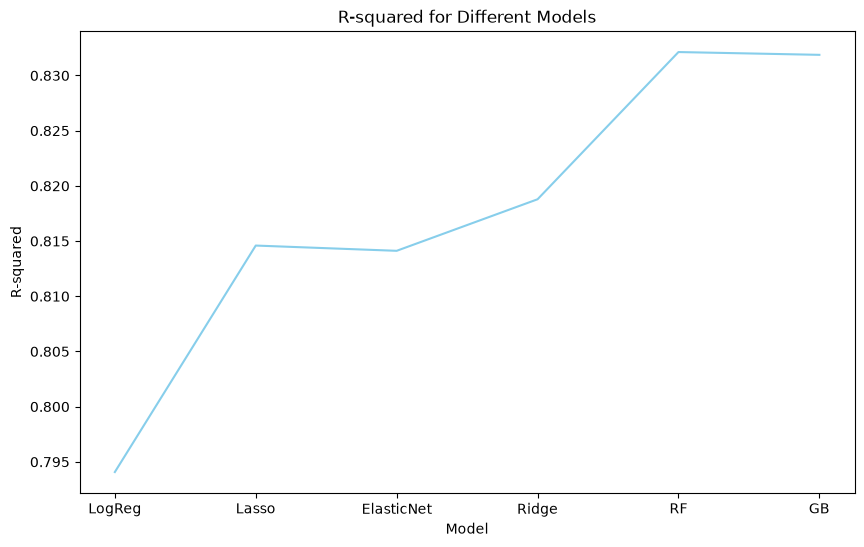

In [48]:
# Plot the metrics for each model using a curve
import matplotlib.pyplot as plt

models_abbr = ['LogReg', 'Lasso', 'ElasticNet', 'Ridge', 'RF', 'GB']

# Plot R-squared
plt.figure(figsize=(10, 6))
plt.plot(models_abbr, metrics_df['R-squared'], color='skyblue')
plt.xlabel('Model')
plt.ylabel('R-squared')
plt.title('R-squared for Different Models')
plt.show()

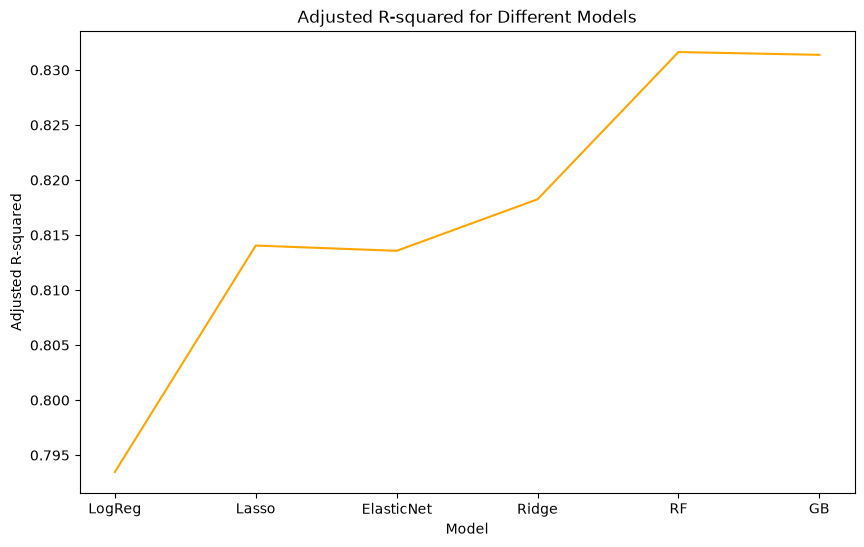

In [49]:
# Plot Adjusted R-squared
plt.figure(figsize=(10, 6))
plt.plot(models_abbr, metrics_df['Adjusted R-squared'], color='orange')
plt.xlabel('Model')
plt.ylabel('Adjusted R-squared')
plt.title('Adjusted R-squared for Different Models')
plt.show()

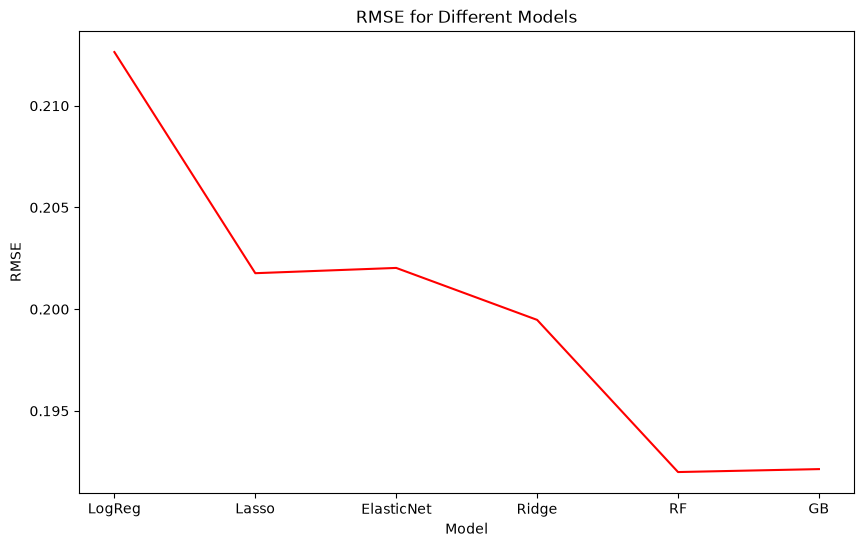

In [50]:
# Plot RMSE
plt.figure(figsize=(10, 6))
plt.plot(models_abbr, metrics_df['RMSE'], color='red')
plt.xlabel('Model')
plt.ylabel('RMSE')
plt.title('RMSE for Different Models')
plt.show()

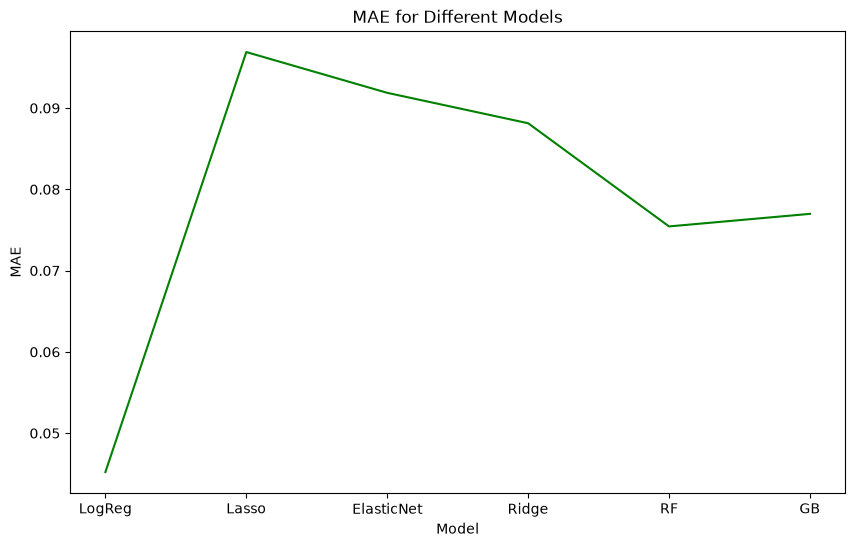

In [51]:
# Plot MAE
plt.figure(figsize=(10, 6))
plt.plot(models_abbr, metrics_df['MAE'], color='green')
plt.xlabel('Model')
plt.ylabel('MAE')
plt.title('MAE for Different Models')
plt.show()

We see from the above table and plots that, based on higher $R^2$ and Adjusted $R^2$, as well as lower RMSE, the Random Forest Regression model works the best in predicting first-year enrollments. Although Logistic Regression has a lower MAE, Gradient Boosting Regression performs better in the other metrics. As a result, the model we will choose will be Gradient Boosting Regression.